# Анализ оттока клиентов телеком-компании

## Цель проекта

Определить основные факторы, связанные с оттоком клиентов, и сформулировать рекомендации по снижению оттока.

## Описание данных

Датасет содержит информацию о клиентах телеком-компании, включая:
- Пол клиента
- Информацию об услугах
- Тип контракта
- Срок сотрудничества
- Ежемесячные платежи
- Факт оттока (Churn)

## Структура анализа

1. Общая доля оттока
2. Анализ оттока по ключевым факторам:
   - Тип контракта
   - Срок сотрудничества (tenure)
   - Тип интернет-услуг
   - Способ оплаты
   - Пол клиента
   - Ежемесячный платёж
3. Выводы и рекомендации

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [9]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [15]:
df['Churn'].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

Ушло ~26% клиентов

In [17]:
df.groupby('gender')['Churn'].apply(lambda x : (x == "Yes").mean())

gender
Female    0.269209
Male      0.261603
Name: Churn, dtype: float64

In [20]:
df.groupby('InternetService')['Churn'].apply(lambda x : (x == "Yes").mean())

InternetService
DSL            0.189591
Fiber optic    0.418928
No             0.074050
Name: Churn, dtype: float64

In [19]:
df.groupby('InternetService')['Churn'].value_counts()

InternetService  Churn
DSL              No       1962
                 Yes       459
Fiber optic      No       1799
                 Yes      1297
No               No       1413
                 Yes       113
Name: count, dtype: int64

Процент оттока у клиентов с интернет провайдером Fiber optic 42%, что намного больше чем у остальных

In [22]:
df.groupby('PaymentMethod')['Churn'].apply(lambda x : (x == "Yes").mean())

PaymentMethod
Bank transfer (automatic)    0.167098
Credit card (automatic)      0.152431
Electronic check             0.452854
Mailed check                 0.191067
Name: Churn, dtype: float64

Также высокий процент оттока у Electronic check, возможно им неудобно пользоваться           

In [24]:
df['tenure'].max()

72

In [26]:
df['tenure_group'] = pd.cut(df['tenure'], bins = [0,12,24,48,72], labels = ['0-12', '13-24', '25-48', '49-72'])


tenure_group
0-12     0.476782
13-24    0.287109
25-48    0.203890
49-72    0.095132
Name: Churn, dtype: float64

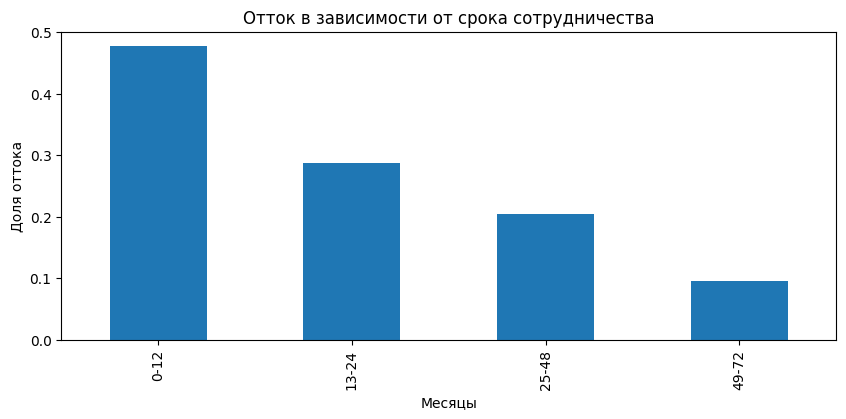

In [66]:
df.groupby('tenure_group')['Churn'].apply(lambda x: (x == 'Yes').mean()).plot(kind = 'bar', figsize=(10, 4))
plt.title('Отток в зависимости от срока сотрудничества')
plt.ylabel('Доля оттока')
plt.xlabel('Месяцы')
plt.show()

In [28]:
df.groupby('SeniorCitizen')['Churn'].apply(lambda x: (x == 'Yes').mean())

SeniorCitizen
0    0.236062
1    0.416813
Name: Churn, dtype: float64

In [29]:
df.groupby('StreamingMovies')['Churn'].apply(lambda x: (x == 'Yes').mean())

StreamingMovies
No                     0.336804
No internet service    0.074050
Yes                    0.299414
Name: Churn, dtype: float64

In [30]:
df['MonthlyCharges'].max()

118.75

Чем меньше клиент сотрудничает, тем больше отток

In [52]:
df['MonthlyChargesGroup'] = pd.cut(df['MonthlyCharges'], bins = [0,20,40,60,80,100,120], labels = ['0-20', '21-40', '41-60', '61-80', '81-100', '101-120'])

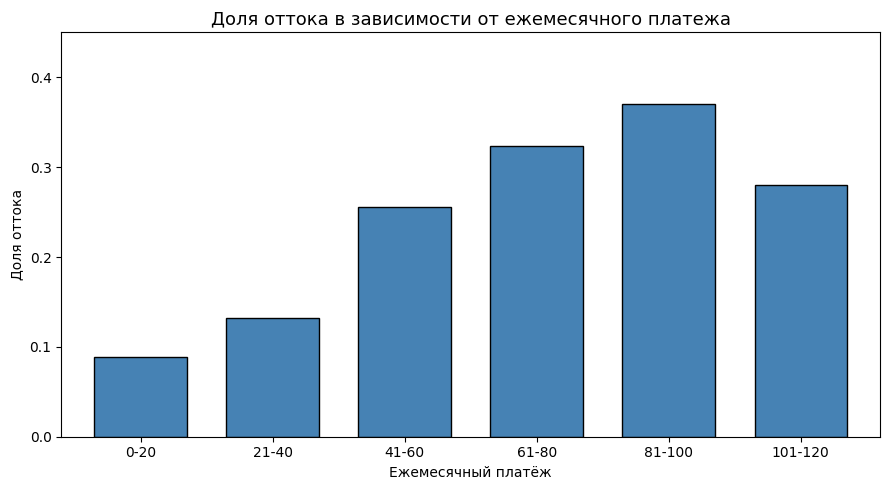

In [59]:
churn_by_group = df.groupby('MonthlyChargesGroup')['Churn'].apply(lambda x: (x == 'Yes').mean())


ax = churn_by_group.plot(
    kind='bar',
    figsize=(9, 5),
    color='steelblue',
    edgecolor='black',
    width=0.7
)


plt.title('Доля оттока в зависимости от ежемесячного платежа', fontsize=13)
plt.xlabel('Ежемесячный платёж')
plt.ylabel('Доля оттока')
plt.ylim(0, churn_by_group.max() + 0.08)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

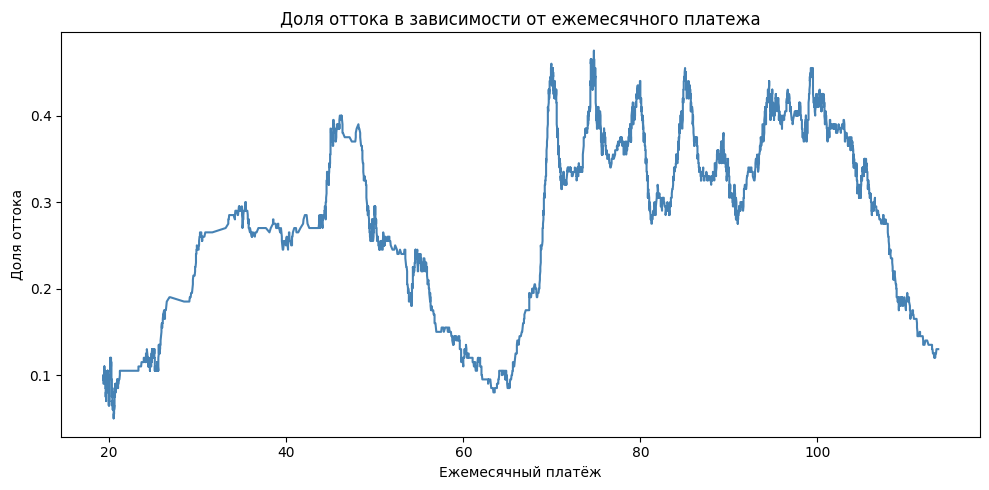

In [61]:
df_sorted = df.sort_values('MonthlyCharges')
df_sorted['churn_flag'] = (df_sorted['Churn'] == 'Yes').astype(int)

# Скользящее среднее
rolling = df_sorted['churn_flag'].rolling(window=200, center=True).mean()

plt.figure(figsize=(10, 5))
plt.plot(df_sorted['MonthlyCharges'], rolling, color='steelblue')
plt.title('Доля оттока в зависимости от ежемесячного платежа')
plt.xlabel('Ежемесячный платёж')
plt.ylabel('Доля оттока')
plt.tight_layout()
plt.show()

Отток растет с ежемесячной платой 

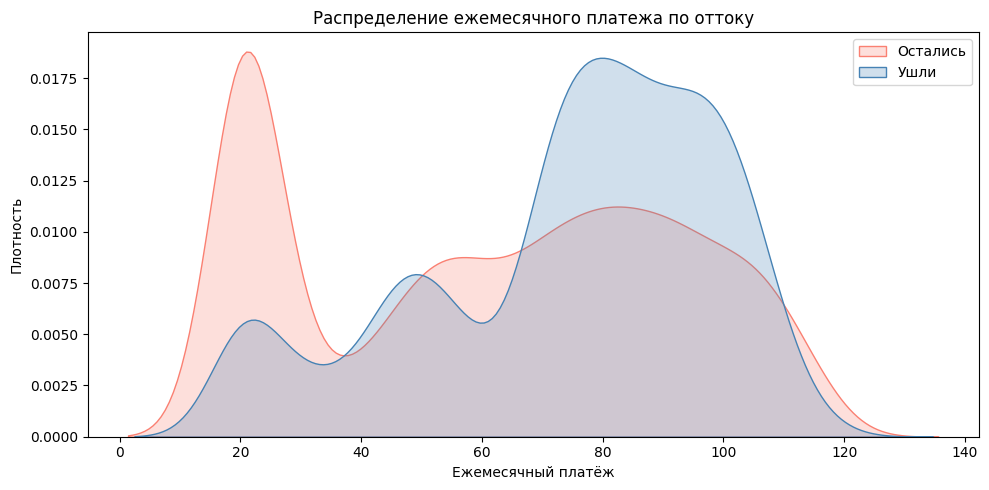

In [57]:
plt.figure(figsize=(10, 5))

sns.kdeplot(data=df[df['Churn'] == 'No'], x='MonthlyCharges', 
            fill=True, label='Остались', color='salmon')
sns.kdeplot(data=df[df['Churn'] == 'Yes'], x='MonthlyCharges', 
            fill=True, label='Ушли', color='steelblue')

plt.title('Распределение ежемесячного платежа по оттоку')
plt.xlabel('Ежемесячный платёж')
plt.ylabel('Плотность')
plt.legend()
plt.tight_layout()
plt.show()

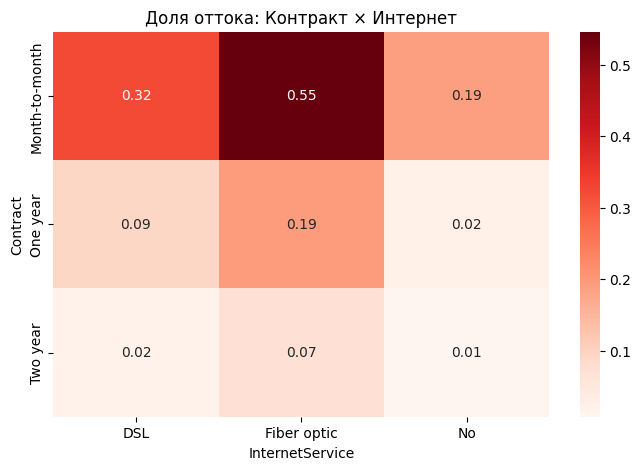

In [71]:
cross = pd.crosstab(
    df['Contract'], 
    df['InternetService'], 
    values=(df['Churn'] == 'Yes'), 
    aggfunc='mean'
)
plt.figure(figsize=(8, 5))
sns.heatmap(cross, annot=True, fmt='.2f', cmap='Reds')
plt.title('Доля оттока: Контракт × Интернет')
plt.show()

Кросс-анализ подтверждает, что основные факторы оттока (тип контракта и тип интернета) сохраняют своё влияние и при совместном рассмотрении. Резких отклонений в сочетаниях факторов не обнаружено.

Вывод: Отток клиентов связан с несколькими ключевыми факторами:

Тип контракта
Наибольший отток наблюдается среди клиентов с помесячным контрактом (Month-to-month). Клиенты с долгосрочными контрактами уходят значительно реже.
Срок сотрудничества
Новые клиенты (особенно в первые 12 месяцев) имеют существенно более высокую вероятность оттока. С увеличением срока сотрудничества лояльность растёт.
Тип интернет-услуг
Клиенты с Fiber optic демонстрируют более высокий отток по сравнению с клиентами на DSL.
Способ оплаты
Оплата электронным чеком (Electronic check) связана с повышенной вероятностью ухода.
Ежемесячный платёж
Наблюдается тенденция к росту оттока при увеличении ежемесячного платежа.

Рекомендации

Стимулировать переход клиентов с помесячных контрактов на долгосрочные.
Усилить сопровождение новых клиентов в первые месяцы.
Проанализировать причины высокого оттока среди пользователей Fiber optic и клиентов с высоким ежемесячным платежом.
Изучить связь между способом оплаты Electronic check и оттоком.